In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error,root_mean_squared_error
import pandas as pd
import matplotlib.pyplot as plt

# Step 1 = Data Loading

In [16]:
df=pd.read_csv("Ice Cream.csv")

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  500 non-null    float64
 1   Revenue      500 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 7.9 KB


In [18]:
df.head()

,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


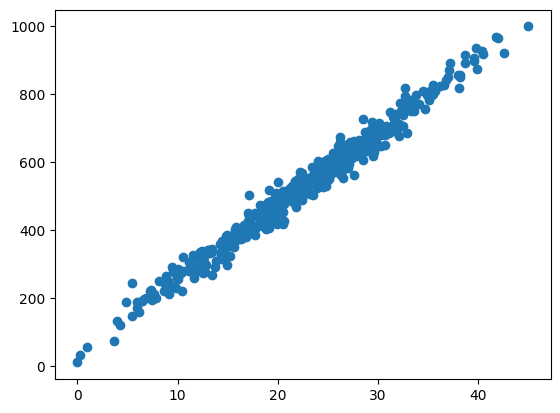

In [19]:
plt.scatter(df['Temperature'], df['Revenue'])

Conclusion : Here the scatter plot follows the linear pattern hence we need to choose linear regression 

In [20]:
df.corr()

,Temperature,Revenue
Temperature,1.000000,0.989841
Revenue,0.989841,1.000000


* Conclusion :

Here the revenue is directly proportional to the Temperature 
Then the correlated value is more than 90% so the revenue is strongly correlated with the Temperature so it follows linear pattern

In [21]:
x=df[['Temperature']]
y=df['Revenue']

In [22]:
x_train,x_test,y_train,y_test= train_test_split(x,y,train_size=0.8,random_state=42)

In [23]:
model=LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[21.38]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,46.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [24]:
model.coef_

array([21.38400073])

Conclusion  :
The rate of change of revenue with respect to temperature in 1 unit is 21.38400073

In [25]:
model.intercept_

46.178345807740584

Conclusion : 46.178345807740584 it is the base or intitial value of revenue when temperature is 0

In [26]:
ytrain_pred=model.predict(x_train)
ytest_pred=model.predict(x_test)

In [31]:
r2_train_score = r2_score(y_train, ytrain_pred)
r2_test_score = r2_score(y_test, ytest_pred)
MAE_train = mean_absolute_error(y_train, ytrain_pred)
MAE_test = mean_absolute_error(y_test, ytest_pred)
RMSE_train = root_mean_squared_error(y_train, ytrain_pred)
RMSE_test = root_mean_squared_error(y_test, ytest_pred)
MSE_train = mean_squared_error(y_train, ytrain_pred)
MSE_test = mean_squared_error(y_test, ytest_pred)



# r2_Score

In [28]:
print("R2 Score for Training Data:", r2_train_score)
print("R2 Score for Testing Data:", r2_test_score)


R2 Score for Training Data: 0.9803485203843681
R2 Score for Testing Data: 0.9771509516333023


Conclusion : 

Here the model captured the data pattern properly it captured nearly 90% of the pattern

Here the test score is also high that shows the  perfomance of the model is also good for future prediction

Thes model captures both train and test data pattern well so it is a good fit model


In [29]:
print("MAE for Training Data:", MAE_train)
print("MAE for Testing Data:", MAE_test)

MAE for Training Data: 19.62008581840379
MAE for Testing Data: 19.195652579103704


In [30]:
print("RMSE for Training Data:", RMSE_train)
print("RMSE for Testing Data:", RMSE_test)

RMSE for Training Data: 24.769530839580312
RMSE for Testing Data: 25.54395874744636


Conclusion:



In [32]:
print("MSE for Training Data:", MSE_train)
print("MSE for Testing Data:", MSE_test)

MSE for Training Data: 613.5296580129202
MSE for Testing Data: 652.4938284912414
